# Chan et al. 2021 — Lung · 02 Manifold

Score the three embryonic modules (Gast/pSom/Crest) with the union control pool → graph-smooth for geography → test proliferation confound → **honest topology test** (PPT tree fork count vs curve) → fit the trajectory, render its edges, check for folds → root from developmental order → pseudotime.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

whole malignant manifold: 50997 cells
UMAP aspect ratio (major/minor std): 1.64


### Score embryonic modules (union control pool) + graph-smooth
`score_genes` with the union pool as `gene_pool` (reference protocol). Raw scores are kept for the deliverable UMAPs; a knn-smoothed copy (`*_sm`, 3 connectivity passes) is used only to read geography and correlations, per the graph-smoothing mandate.

In [4]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global raw means:', {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']})

Gast: 80/81 genes present
pSom: 96/98 genes present
Crest: 104/104 genes present
global raw means: {'Gast': 0.0365, 'pSom': 0.1113, 'Crest': -0.0801}


### Module geography + proliferation-confound check
Smoothed spatial correlations reveal the pattern; Spearman vs g1s/g2m tests whether any module is a proliferation artifact (the Kürten/Chen lobe-confound fork).

In [5]:
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('pSom_sm','Crest_sm'),('Gast_sm','Crest_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
print('module vs proliferation (Spearman rho):')
for m in ['Gast','pSom','Crest']:
    print(f'  {m}: vs g2m {spearmanr(g2m,adata.obs[m])[0]:+.2f}  vs g1s {spearmanr(g1s,adata.obs[m])[0]:+.2f}')
print('-> |rho|<=0.15: developmental modules are NOT proliferation-confounded; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.28
  pSom_sm vs Crest_sm: r = -0.89
  Gast_sm vs Crest_sm: r = -0.35
module vs proliferation (Spearman rho):
  Gast: vs g2m -0.15  vs g1s -0.10
  pSom: vs g2m +0.06  vs g1s -0.15
  Crest: vs g2m -0.02  vs g1s +0.12
-> |rho|<=0.15: developmental modules are NOT proliferation-confounded; keep whole manifold (no scoping).


### Honest topology test — PPT tree fork count vs curve
Fit a scFates PPT **tree** across a parameter grid and count branch (fork) nodes. A genuine bifurcation gives one dominant fork with two gradient-opposed arms; a compact 2-D cloud instead produces many spurious forks as the tree tiles the blob. Here the tree over-forks and the biology (Gast/pSom co-vary, Crest inverse) is non-branching, so a **curve** is the correct topology.

In [6]:
def tree_forks(N, lam):
    ad = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=N, ppt_lambda=lam, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(ad.uns['graph']['B']); deg=(B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree branch-node scan (Nodes,lambda -> tips, forks):')
for N in [100,200,300]:
    for lam in [1000,2000]:
        tips,forks = tree_forks(N,lam); print(f'  N={N} lam={lam} -> tips={tips} forks={forks}')
print('-> tree over-forks a compact cloud (no single dominant Y); non-branching -> fit a curve.')

PPT tree branch-node scan (Nodes,lambda -> tips, forks):
  N=100 lam=1000 -> tips=11 forks=9
  N=100 lam=2000 -> tips=10 forks=8
  N=200 lam=1000 -> tips=17 forks=15
  N=200 lam=2000 -> tips=12 forks=10
  N=300 lam=1000 -> tips=17 forks=15
  N=300 lam=2000 -> tips=16 forks=14
-> tree over-forks a compact cloud (no single dominant Y); non-branching -> fit a curve.


### Fit curve + fold diagnostic
Elastic principal curve on the existing `X_umap` (no re-embedding of a linear compartment). The self-approach ratio (min graph-distant node distance / median edge) > 1 certifies a fold-free curve; 0 forks confirms the single axis.

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    scf.tl.curve(sub, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.78 (>1 = fold-free)


### Root from developmental order
Crest is a **late** readout; the root belongs at the Gast/pSom-high (Crest-low) tip. Tip neighbourhoods are scored on the smoothed developmental coordinate `dev = z(Crest_sm) - z(pSom_sm)`; the minimal-`dev` tip (most progenitor) is the root.

In [8]:
z = lambda x: (x - x.mean())/x.std()
sub.obs['dev'] = z(sub.obs['Crest_sm']) - z(sub.obs['pSom_sm'])   # high = terminal Crest
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
Dg = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(Dg[tp]<=4)[0])
    info[tp] = (sub.obs.Gast_sm[m].mean(), sub.obs.pSom_sm[m].mean(), sub.obs.Crest_sm[m].mean(), sub.obs.dev[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} dev={info[tp][3]:+.2f}')
root = int(min(tps, key=lambda tp: info[tp][3]))
print('derived root = tip', root, '(min dev = pSom/Gast-high, Crest-low progenitor)')
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','dev']:
    print(f'  {s_}: rho={spearmanr(t, sub.obs[s_])[0]:+.3f}')
print(f'  g2m_score: rho={spearmanr(t, g2m)[0]:+.3f}  (proliferation falls along the axis)')

tip 0: Gast=+0.0395 pSom=+0.1034 Crest=-0.0792 dev=+0.31
tip 2: Gast=+0.0177 pSom=+0.1256 Crest=-0.0936 dev=-1.53
derived root = tip 2 (min dev = pSom/Gast-high, Crest-low progenitor)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.443
  pSom_sm: rho=-0.233
  Crest_sm: rho=+0.143
  dev: rho=+0.195
  g2m_score: rho=-0.645  (proliferation falls along the axis)


### Save manifold.h5ad + manifold.pdf (pseudotime, house orientation)

saved manifold.h5ad + manifold.pdf


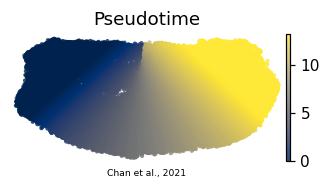

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')